# Gender Gap in STEM: An Exploratory Data Analysis

## Objective
This project explores how the percentage of bachelor's degrees awarded to women in the USA has changed over time, with a focus on STEM fields such as Computer Science and Engineering.

## Data source
- Dataset: *Percentage of Bachelor's degrees done by women USA* (Kaggle, uploaded by Yogesh Kumar Singla)
- Original data compiled by Randal Olson from U.S. Department of Education statistics

## Tools
Python, pandas, Matplotlib

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yogeshkumarsingla/percentage-of-bachelors-degrees-done-by-women-usa/percent-bachelors-degrees-women-usa.csv


In [3]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/yogeshkumarsingla/percentage-of-bachelors-degrees-done-by-women-usa/percent-bachelors-degrees-women-usa.csv")
df.head()

,Year,Agriculture,Architecture,Art and Performance,Biology,Business,Communications and Journalism,Computer Science,Education,Engineering,English,Foreign Languages,Health Professions,Math and Statistics,Physical Sciences,Psychology,Public Administration,Social Sciences and History
0,1970,4.229798,11.921005,59.7,29.088363,9.064439,35.3,13.6,74.535328,0.8,65.570923,73.8,77.1,38.0,13.8,44.4,68.4,36.8
1,1971,5.452797,12.003106,59.9,29.394403,9.503187,35.5,13.6,74.149204,1.0,64.556485,73.9,75.5,39.0,14.9,46.2,65.5,36.2
2,1972,7.420710,13.214594,60.4,29.810221,10.558962,36.6,14.9,73.554520,1.2,63.664263,74.6,76.9,40.2,14.8,47.6,62.6,36.1
3,1973,9.653602,14.791613,60.2,31.147915,12.804602,38.4,16.4,73.501814,1.6,62.941502,74.9,77.4,40.9,16.5,50.4,64.3,36.4
4,1974,14.074623,17.444688,61.9,32.996183,16.204850,40.5,18.9,73.336811,2.2,62.413412,75.3,77.9,41.8,18.2,52.6,66.1,37.3


In [4]:
print(df.shape)
print(df.columns.tolist())
df.info()
print(df.isnull().sum())
print(df.duplicated().sum())

(42, 18)
['Year', 'Agriculture', 'Architecture', 'Art and Performance', 'Biology', 'Business', 'Communications and Journalism', 'Computer Science', 'Education', 'Engineering', 'English', 'Foreign Languages', 'Health Professions', 'Math and Statistics', 'Physical Sciences', 'Psychology', 'Public Administration', 'Social Sciences and History']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Year                           42 non-null     int64  
 1   Agriculture                    42 non-null     float64
 2   Architecture                   42 non-null     float64
 3   Art and Performance            42 non-null     float64
 4   Biology                        42 non-null     float64
 5   Business                       42 non-null     float64
 6   Communications and Journalism  42 non-null     float64
 7   Computer

## Data overview
The dataset contains 42 rows (one per year) and 18 columns (the year and 17 fields of study). Each value is the percentage of bachelor's degrees awarded to women in that field.

I checked the data quality: there are no missing values and no duplicate rows, so no cleaning was needed.

In [10]:
print(df["Year"].min(), df["Year"].max())
df[["Year","Computer Science","Engineering","Biology"]].head()

1970 2011


,Year,Computer Science,Engineering,Biology
0,1970,13.6,0.8,29.088363
1,1971,13.6,1.0,29.394403
2,1972,14.9,1.2,29.810221
3,1973,16.4,1.6,31.147915
4,1974,18.9,2.2,32.996183


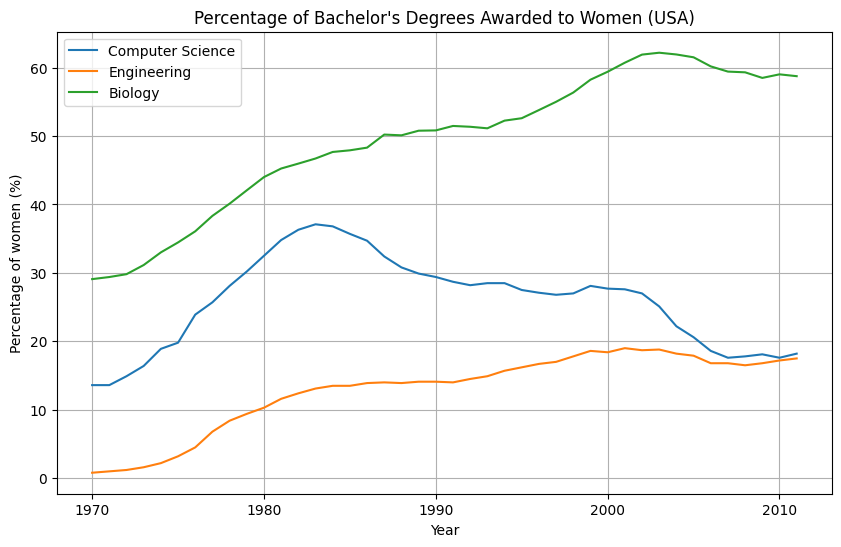

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(df["Year"], df["Computer Science"], label="Computer Science")
plt.plot(df["Year"], df["Engineering"], label="Engineering")
plt.plot(df["Year"], df["Biology"], label="Biology")

plt.title("Percentage of Bachelor's Degrees Awarded to Women (USA)")
plt.xlabel("Year")
plt.ylabel("Percentage of women (%)")
plt.legend()
plt.grid(True)
plt.show()

## Key findings

- **Biology**: The share of women went up from about 29% in 1970 to about 60% in the early 2000s. It has stayed high since then.
- **Engineering**: The share of women started very low (about 1% in 1970). It grew to about 17-18% and stayed almost the same after the 1990s.
- **Computer Science**: The share of women went up from about 14% in 1970 to about 37% in the mid-1980s. After that, it went down to about 18% in 2011.

The fall in Computer Science is the most surprising result. Other fields did not show the same trend. In the next steps, I would like to look for possible reasons for this change.